In [79]:
import numpy as np
import scipy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import train_test_split

Read 3 csv from documents

In [80]:
property = pd.read_csv("/content/drive/MyDrive/Data/properties_2022.csv")
sales = pd.read_csv("/content/drive/MyDrive/Data/sales.csv")
var_dict = pd.read_csv("/content/drive/MyDrive/Data/variable_dictionary.csv")

/tmp/ipykernel_569/1186188372.py:1: DtypeWarning: Columns (37) have mixed types. Specify dtype option on import or set low_memory=False.
  property = pd.read_csv("/content/drive/MyDrive/Data/properties_2022.csv")


Check the circumstance of missing value in property and
sales csv. Check whether the missing value fraction in
property csv approximately equals to that in dictionary

初步检查两份文件的数据，包括日期的合理性、price的合理性、缺失值情况


In [81]:
print (property.info())
print ("\nThe shape of property dataset is: {}\n".format(property.shape))

act_missing = property.drop(columns='property_id').isnull().mean()

var_dict["actual_missing_fraction"] = var_dict["variable"].map(act_missing)
difference = (var_dict["actual_missing_fraction"] - var_dict["missing_fraction"])
great_diff = difference[difference>1e-6]

unmatched = act_missing.index[~act_missing.index.isin(var_dict["variable"])]

if great_diff.empty and unmatched.empty:
  print ("All null fraction in property csv can match with that in dictionary\n and features are all included in dictionary")
else:
  print (great_diff)
  print (unmatched)

value_null = property.isnull().sum().sort_values(ascending=False)
cols_with_missing = property.isnull().any(axis=0).sum()
print ("\nNumber of columns with missing values in property csv: ",cols_with_missing)
print ("\nSum of missing value:\n", value_null[value_null!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98899 entries, 0 to 98898
Data columns (total 98 columns):
 #   Column                                                 Non-Null Count  Dtype  
---  ------                                                 --------------  -----  
 0   property_id                                            98899 non-null  int64  
 1   loc_property_city                                      98897 non-null  object 
 2   loc_property_zip                                       98517 non-null  float64
 3   loc_longitude                                          98899 non-null  float64
 4   loc_latitude                                           98899 non-null  float64
 5   char_yrblt                                             98898 non-null  float64
 6   char_bldg_sf                                           98899 non-null  float64
 7   char_land_sf                                           98899 non-null  float64
 8   char_beds                                     

上述property csv中，所有feature均已被dictionary涵盖，且missing fraction与dictionary基本一致。
总计样本数98899，总feature数量为97+1（1为property_id），含缺失值的feature总共有39个

In [82]:
print (sales.info())
print ("\nThe shape of property dataset is: {}\n".format(sales.shape))
value_null2 = sales.isnull().sum().sort_values(ascending=False)

if value_null2.empty:
  print ("No missing value in sales csv")
else:
  print (value_null2[value_null2!=0])


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 109307 entries, 0 to 109306
Data columns (total 4 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   property_id     109307 non-null  int64  
 1   transaction_id  109307 non-null  int64  
 2   sale_date       109307 non-null  object 
 3   sale_price      109307 non-null  float64
dtypes: float64(1), int64(2), object(1)
memory usage: 3.3+ MB
None

The shape of property dataset is: (109307, 4)

Series([], dtype: int64)


上述Sales csv中总计109307个样本，feature数量为3+1（包含1个property_id）。没有missing value

According to the above, there are a large amount of missing
value in property csv, and their fraction can match to
that in dictionary. No missing value exist in sales csv.


---


Confirm whether there are records out of required time

In [83]:
sales['sale_date'] = pd.to_datetime(sales['sale_date'])

# Confirm whether there are records out of required time
outoftime = sales[(sales['sale_date'] >= '2026-01-01')|(sales['sale_date'] <= '2022-12-31')]

if outoftime.empty:
  print ('All records in sale csv fall within 2023 and 2025\n')
else:
  print ('There are sale records out of specified time:\n{}'.format(outoftime))

print("char_yrblt range:", property["char_yrblt"].min(),property["char_yrblt"].max())
print("Later than 2022 char_built:",(property["char_yrblt"]>2022).sum())
print("Null or negative record:",(property["char_yrblt"] <= 0).sum())
print("Too early (<1800) :", (property["char_yrblt"]< 1800).sum())

print("\nRange of year Median Occupied Household:",property["acs5_median_household_total_occupied_year_built"].min(),
      property["acs5_median_household_total_occupied_year_built"].max())
print("Later than 2022 Median Occupied Household:",
 (property["acs5_median_household_total_occupied_year_built"] > 2022).sum())

illegal_price = sales[sales['sale_price']<=0]

if illegal_price.empty:
  print ('\nAll records in sale csv have proper price\n')
else:
  print ('There are sale records within illegal price:\n{}'.format(illegal_price))


All records in sale csv fall within 2023 and 2025

char_yrblt range: 1847.0 2021.0
Later than 2022 char_built: 0
Null or negative record: 0
Too early (<1800) : 0

Range of year Median Occupied Household: 1940.0 2007.0
Later than 2022 Median Occupied Household: 0

All records in sale csv have proper price



All records in sales csv and property csv are correctly
recorded.

上述时间检查中，sales和property中的records的时间，均被记录在正确范围内。
对于sales csv中的价格数据，均在0值以上，没有非法数据记录。

---


We then test whether duplicate records and repeated
sales of the same property exist or not.

:

In [84]:
duplicate_trans_id = sales['transaction_id'].value_counts()
duplicate_list = duplicate_trans_id[duplicate_trans_id>1]
if duplicate_list.empty:
  print ('No duplicated transaction id exist.')
else:
  print ('There are duplicated transaction id existing:\n{}'.format(duplicate_list))

print ("Number of unique transaction id in sales csv: ",sales['transaction_id'].nunique())
print ("Number of unique property id in sales csv: ",sales['property_id'].nunique())
print ("Number of unique property id in property csv: ",property['property_id'].nunique())

print ("Sales shape: ",sales.shape)
print ("Property shape: ",property.shape)

# 将property id出现的统计值添加回原始DataFrame，进行分组
sales["sale_count"] = sales.groupby("property_id")["transaction_id"].transform("count")
# boolean shows property id是否重复销售
sales["is_repeat_sale"] = sales["sale_count"] > 1

print (sales["sale_count"].min()== 1)
print ((sales["is_repeat_sale"] == (sales["sale_count"] > 1)).all())

# # 检查是否存在重复的property id中，有同一日期的不同销售记录
# repeat_sales = sales[sales["is_repeat_sale"] == True]
# result = (repeat_sales.groupby("property_id")["sale_date"].nunique().le(1).all())
# print(result)

No duplicated transaction id exist.
Number of unique transaction id in sales csv:  109307
Number of unique property id in sales csv:  98899
Number of unique property id in property csv:  98899
Sales shape:  (109307, 4)
Property shape:  (98899, 98)
True
True


From the above, we can find that in the property csv,
all of the property id is unique. However, in the sales
csv, the number of property id does not equal to the
row number, which means that there are duplicated property id
existing. Transaction id is unique. This means that one
property id may match mulitple transaction id, which is
compliant.

上述检查中，sales csv中的transaction id的独立值数量总计109307，与行数一致，故transaction是完全相互独立，不存在重复销售的情况。

property csv中的property id的独立值总计98899，和csv的行数一致，不存在重复的property信息被记录的情况。

而sales csv中的property id的独立值数量总计为98899，小于109307，故存在同一property有着多笔交易的出现，这符合实际情况和预期。而其独立值数量与property csv的数量一致，初步判断两边property id的独立值在数量和value上是相等的，还需进一步判断

上述检查中，还对存在重复交易的property做出额外标识（sale_count，is_repeat_sale）用于后续操作处理。

---


Set the first column 'property_id' as index

In [85]:
property = property.set_index ('property_id')
print (property.head())
sales = sales.set_index ('property_id')
print (sales.head())

              loc_property_city  loc_property_zip  loc_longitude  \
property_id                                                        
1011000170000        BARRINGTON           60010.0     -88.140521   
1011000190000        BARRINGTON           60010.0     -88.140083   
1011000250000        BARRINGTON           60010.0     -88.138667   
1011000430000        BARRINGTON           60010.0     -88.138708   
1011000460000        BARRINGTON           60010.0     -88.137997   

               loc_latitude  char_yrblt  char_bldg_sf  char_land_sf  \
property_id                                                           
1011000170000     42.153671      1893.0        1584.0        9027.0   
1011000190000     42.153577      1940.0         807.0        6699.0   
1011000250000     42.153573      1930.0        1248.0        5040.0   
1011000430000     42.153038      1935.0        1366.0        8712.0   
1011000460000     42.153036      1888.0        1823.0        7933.0   

               char_beds 

下面进一步检测sales中的property id独立值是否与property csv中的独立值一致，不存在哪一边有对方不存在的独立值

In [86]:
unmatched_index = sales.index[~sales.index.isin(property.index)]
unmatched_index2 = property.index[~property.index.isin(sales.index)]

if unmatched_index.empty and unmatched_index2.empty:
  print ("\nAll property_id can be matched between property csv and sales csv. \n")
else:
  print (unmatched_index)
  print (unmatched_index2)


All property_id can be matched between property csv and sales csv. 



上述检测可得出，property_id在sales和property csv中独立值完全一致。

通过上述所有的检验，我们进行两表的合并，以sales csv为主表，将property数据匹配插入

In [87]:
property_list = pd.merge(sales, property, left_index=True, right_index=True, how = 'left', validate = 'many_to_one')
print (property_list.shape)
print (property_list.info())

(109307, 102)
<class 'pandas.core.frame.DataFrame'>
Index: 109307 entries, 4211120100000 to 32363060100000
Columns: 102 entries, transaction_id to meta_cdu
dtypes: bool(4), datetime64[ns](1), float64(81), int64(12), object(4)
memory usage: 83.0+ MB
None


合并后的表格行数109307，和sales一致；columns数据为102=97+2+3，其中97和3分别为property和sales的features数量，2为property中新增的两列用于标识重复交易的property

---


Check again the missing value

In [88]:
value_null3 = property_list.isnull().sum().sort_values(ascending=False)
print (value_null3[value_null3!=0])

value_null_frac = property_list.isnull().mean().sort_values(ascending=False)
print ('\n',value_null_frac[value_null_frac!=0])

loc_tax_special_service_area_num                    106181
loc_school_unified_district_geoid                   105378
loc_tax_tif_district_num                            100073
loc_chicago_community_area_name                      65215
loc_chicago_ward_num                                 65215
char_tp_dsgn                                         58644
char_tp_plan                                         30998
prox_avg_school_rating_in_half_mile                  27086
acs5_median_household_total_occupied_year_built      24145
char_gar1_cnst                                       17977
other_school_district_elementary_avg_rating           4250
other_school_district_secondary_avg_rating            4057
loc_school_elementary_district_geoid                  3929
loc_school_secondary_district_geoid                   3929
acs5_median_household_renter_occupied_gross_rent      2770
char_apts                                              969
prox_num_foreclosure_per_1000_pin_past_5_years         8

Handle missing value, according to fraction and dictionary

根据dictionary内的定义来预先处理部分missing value

①处理char_type_resd的missing定义

In [89]:
# match codes with variables that have missing value
match_code = (
    var_dict
    .set_index("variable")
    .reindex(value_null_frac.index)[["type", "codes", "definition", "missing_fraction"]]
)
print (match_code[match_code["codes"].notna()]["codes"])

# char_type_resd, dictionary provides 9.9 = Missing
property_list['char_type_resd'] = property_list['char_type_resd'].fillna(9.9)


char_tp_dsgn                                         1 = Yes; 2 = No
char_tp_plan                           1 = Architect; 2 = Stock Plan
char_gar1_cnst     1 = Frame; 2 = Masonry; 3 = Frame + Masonry; 4...
char_apts          1 = Two; 2 = Three; 3 = Four; 4 = Five; 5 = Si...
char_gar1_att                                        1 = Yes; 2 = No
char_gar1_area                                       1 = Yes; 2 = No
char_type_resd     1 = 1 Story; 2 = 2 Story; 3 = 3 Story +; 4 = S...
char_porch         0 = None; 1 = Frame Enclosed; 2 = Masonry Encl...
char_attic_fnsh               1 = Living Area; 2 = Partial; 3 = None
char_heat          1 = Warm Air Furnace; 2 = Hot Water Steam; 3 =...
char_bsmt_fin      1 = Formal Rec Room; 2 = Apartment; 3 = Unfini...
char_gar1_size     1 = 1 cars; 2 = 1.5 cars; 3 = 2 cars; 4 = 2.5 ...
char_air                         1 = Central A/C; 2 = No Central A/C
char_bsmt                 1 = Full; 2 = Slab; 3 = Partial; 4 = Crawl
char_roof_cnst     1 = Shingle + A

②处理definition对feature的missing有定义的部分

验证ward_num和chicago_community_loc的missing value sample的一致
验证property_city和ward_num对于是否chicago上并非一致

In [90]:
# match definition with variables that have missing value
print ('\n',match_code[match_code["definition"].notna()]["definition"])

# missing in loc_chicago_ward_num means outside Chicago
# meanwhile, loc_property_city provide located city, including Chicago
# Also, we check loc_chicago_community_area_name's relation with loc_chicago_ward_num, since both have same fraction
diff2 = property_list["loc_chicago_ward_num"].notna().equals(property_list["loc_chicago_community_area_name"].notna())
print ('\nWhether missing value rows are the same between loc_chicago_ward_num and loc_chicago_community_area_name: ',diff2)

# So both missing value can use a similar rule to fill
# However, for loc_property_city and loc_chicago_ward_num, one shows Chicago but the other is not
identify1 = property_list["loc_chicago_ward_num"].notna()
identify2 = property_list["loc_property_city"].notna()
diff3 = property_list[identify1 & identify2]["loc_property_city"] == 'CHICAGO'
print ('\nWhether loc_chicago_ward_num notna value rows have CHICAGO label in loc_property_city: ',diff3.all())




 loc_tax_special_service_area_num                                          Special Service Area Number
loc_school_unified_district_geoid                                       School Unified District GEOID
loc_tax_tif_district_num                                                          TIF District Number
loc_chicago_community_area_name                                           Chicago Community Area Name
loc_chicago_ward_num                                Chicago ward code. Usually missing outside Chi...
                                                                          ...                        
acs5_percent_employment_unemployed                          Percent Population Employment, Unemployed
acs5_percent_household_total_occupied_w_sel_cond    Percent Occupied Households, Total, One or Mor...
meta_class                                                                             Property Class
meta_nbhd_code                                                                  

由于ward_num和property_city都能代表Chicago相关，根据两边共同建立is_Chicago的missing indicator并且判断。通过crosstab判断ward_num显示缺失与“is_Chicago”是否高度重合

In [91]:
# we combine loc_chicago_ward_num and loc_property_city to set a new column identifier is_Chicago
is_Chicago = (property_list["loc_chicago_ward_num"].notna()
| (property_list["loc_property_city"].str.strip().str.lower() == 'chicago'))

property_list['is_Chicago'] = is_Chicago.astype(int)

pd.crosstab(
    property_list["is_Chicago"],
    property_list["loc_chicago_ward_num"].isna(),
    margins=True
)



loc_chicago_ward_num,False,True,All
is_Chicago,,,
0,0,65147,65147
1,44092,68,44160
All,44092,65215,109307


对property_city,ward_num,chicago_community_area的missing value进行填补

In [92]:
# Since loc_property_city only has 2 missing value, we replace it with CHICAGO or Unknown
city = property_list["loc_property_city"].astype("object")

mask_city_missing = city.isnull()
city[mask_city_missing & (property_list["is_Chicago"] == 1)] = "CHICAGO"
city[mask_city_missing & (property_list["is_Chicago"] == 0)] = "UNKNOWN"

property_list["loc_property_city"] = city

# Since loc_chicago_ward_num has 59% missing fraction, we have 2 choices to replace NaN
ward = property_list["loc_chicago_ward_num"].astype("object")

mask_A = ward.isnull() & (property_list["is_Chicago"] == 1)
ward[mask_A] = "Chicago-Unknown"
mask_B = ward.isnull() & (property_list["is_Chicago"] == 0)
ward[mask_B] = "Non-Chicago"

property_list["loc_chicago_ward_num"] = ward

# Similarly, loc_chicago_community_area_name can follow the same rule to replace NaN
Area = property_list["loc_chicago_community_area_name"].astype("object")

mask_A = Area.isnull() & (property_list["is_Chicago"] == 1)
Area[mask_A] = "Chicago-Unknown"
mask_B = Area.isnull() & (property_list["is_Chicago"] == 0)
Area[mask_B] = "Non-Chicago"

property_list["loc_chicago_community_area_name"] = Area



以上missing value填补采用的是Structural Imputation，不存在leakage问题。后续我们优先对DF进行split，然后再来填补missing value

我们对sales price进行EDA分析

Transactions by year:
sale_year
2023    37520
2024    35465
2025    36322
dtype: int64
sale_quarter     1      2      3     4
sale_year                             
2023          7552  11211  10360  8397
2024          7308  10025   9768  8364
2025          7074  10563  10094  8591


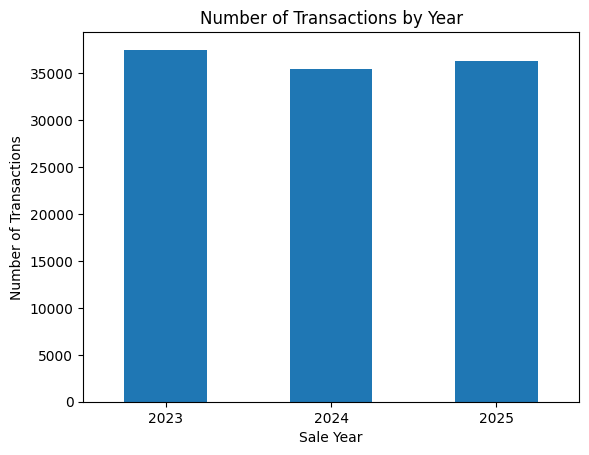

In [93]:
sales_property = property_list.copy()

sales_property['sale_year'] = sales_property['sale_date'].dt.year
sales_property['sale_quarter'] = sales_property['sale_date'].dt.quarter
sales_property['sale_month'] = sales_property['sale_date'].dt.month

year_counts = sales_property.groupby('sale_year').size()

print("Transactions by year:")
print(year_counts)

quarter_counts = sales_property.groupby(
    ['sale_year', 'sale_quarter']
).size().unstack(fill_value=0)

print(quarter_counts)

year_counts.plot(kind='bar')
plt.title('Number of Transactions by Year')
plt.xlabel('Sale Year')
plt.ylabel('Number of Transactions')
plt.xticks(rotation=0)
plt.show()


In [94]:
year_price_summary = sales_property.groupby('sale_year')['sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

print(year_price_summary.round(2))


           count       mean    median        std      min         max
sale_year                                                            
2023       37520  406135.87  315000.0  382418.53  10650.0  12500000.0
2024       35465  447427.17  345000.0  423080.67  10639.0  15250000.0
2025       36322  475125.26  360000.0  492688.24  11000.0  32500000.0


从上述结果看出，3年间sale price的中位数和均值都有着明显的上涨，而25年存在非常大的极端值325万USD，这将影响我们进一步EDA的分析，因而我们下面采用log transform来抵消极端值产生的影响

           count   mean  median   std   min    max
sale_year                                         
2023       37520  12.63   12.66  0.77  9.27  16.34
2024       35465  12.73   12.75  0.75  9.27  16.54
2025       36322  12.78   12.79  0.76  9.31  17.30


<Figure size 900x500 with 0 Axes>

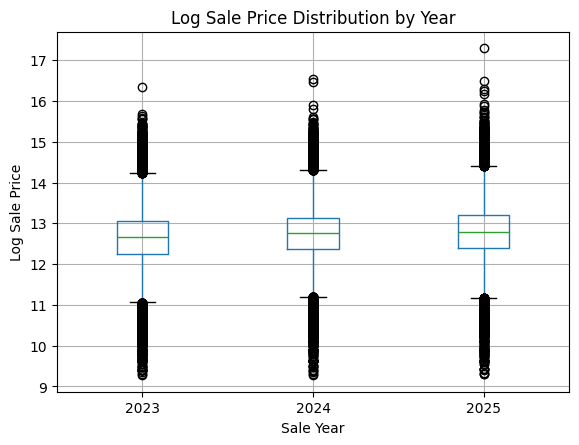

In [95]:
# Already checked that all sale prices are larger than 0
# use log transform to offset the influence of extreme value
sales_property['log_sale_price'] = np.log1p(sales_property['sale_price'])

year_logprice_summary = sales_property.groupby('sale_year')['log_sale_price'].agg(
    count='count',
    mean='mean',
    median='median',
    std='std',
    min='min',
    max='max'
)

plt.figure(figsize=(9, 5))

print(year_logprice_summary.round(2))

# Draw the boxplot to find
sales_property.boxplot(
    column='log_sale_price',
    by='sale_year'
)

plt.title('Log Sale Price Distribution by Year')
plt.suptitle('')
plt.xlabel('Sale Year')
plt.ylabel('Log Sale Price')
plt.show()

Form the above

从上图看出，采用log变换后，我们再一次对按年划分的log sale price进行分析并构筑boxplot。可以看到，三年间价格中位数处于上涨趋势，价格的IQR大致相同，而std水平也没有明显波动（0.75-0.77）。


---


我们再对季节指标进行EDA分析

                        count   mean  median
sale_year sale_quarter                      
2023      1              7552  12.54   12.58
          2             11211  12.67   12.71
          3             10360  12.67   12.71
          4              8397  12.59   12.64
2024      1              7308  12.62   12.66
          2             10025  12.79   12.79
          3              9768  12.77   12.78
          4              8364  12.70   12.74
2025      1              7074  12.71   12.74
          2             10563  12.82   12.83
          3             10094  12.81   12.81
          4              8591  12.75   12.79


<Figure size 1000x500 with 0 Axes>

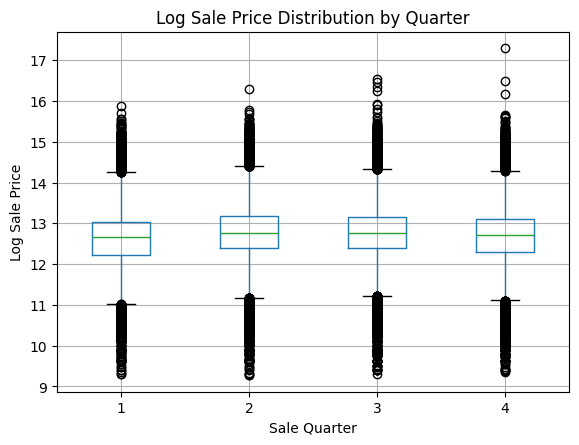

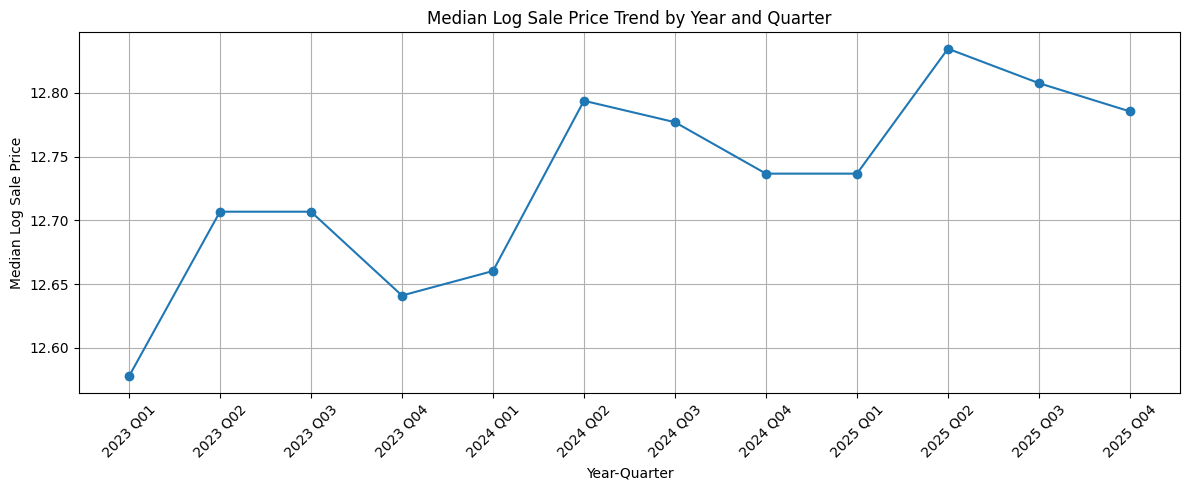

In [96]:
quarter_logprice_summary = sales_property.groupby(
    ['sale_year', 'sale_quarter']
)['log_sale_price'].agg(
    count='count',
    mean='mean',
    median='median'
)

print(quarter_logprice_summary.round(2))

plt.figure(figsize=(10, 5))

sales_property.boxplot(
    column='log_sale_price',
    by='sale_quarter',
)
plt.title('Log Sale Price Distribution by Quarter')
plt.suptitle('')
plt.xlabel('Sale Quarter')
plt.ylabel('Log Sale Price')
plt.show()

quarter_trend = sales_property.groupby(['sale_year', 'sale_quarter'])['log_sale_price'].median().reset_index()

quarter_trend['year_quarter'] = quarter_trend['sale_year'].astype(str) + ' Q' + quarter_trend['sale_quarter'].astype(str).str.zfill(2)

plt.figure(figsize=(12, 5))
plt.plot(quarter_trend['year_quarter'], quarter_trend['log_sale_price'], marker='o', linestyle='-')
plt.xticks(rotation=45)  # 倾斜 X 轴标签防止重叠
plt.title('Median Log Sale Price Trend by Year and Quarter')
plt.xlabel('Year-Quarter')
plt.ylabel('Median Log Sale Price')
plt.grid(True)
plt.tight_layout()
plt.show()

                      count   mean  median
sale_year sale_month                      
2023      1            1973  12.47   12.52
          2            2274  12.53   12.57
          3            3305  12.60   12.61
          4            3217  12.63   12.68
          5            3847  12.67   12.70
          6            4147  12.71   12.74
          7            3529  12.69   12.72
          8            3682  12.67   12.71
          9            3149  12.65   12.68
          10           3101  12.58   12.63
          11           2686  12.62   12.66
          12           2610  12.57   12.61
2024      1            2044  12.56   12.60
          2            2377  12.59   12.63
          3            2887  12.70   12.73
          4            3186  12.74   12.76
          5            3478  12.80   12.82
          6            3361  12.83   12.83
          7            3485  12.82   12.81
          8            3297  12.76   12.77
          9            2986  12.74   12.76
          1

<Figure size 1000x500 with 0 Axes>

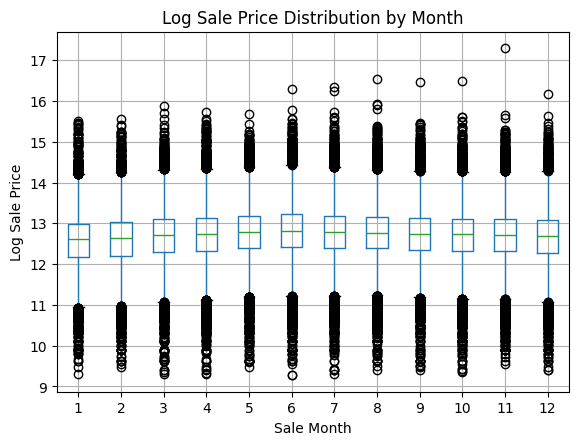

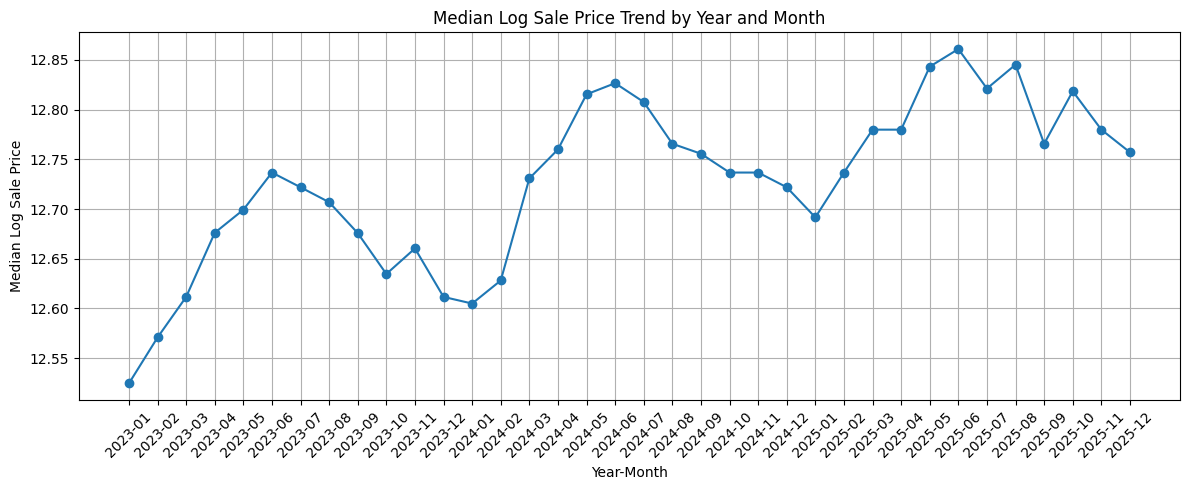

In [97]:
month_logprice_summary = sales_property.groupby(
    ['sale_year', 'sale_month']
)['log_sale_price'].agg(
    count='count',
    mean='mean',
    median='median'
)

print(month_logprice_summary.round(2))

plt.figure(figsize=(10, 5))

sales_property.boxplot(
    column='log_sale_price',
    by='sale_month',
)
plt.title('Log Sale Price Distribution by Month')
plt.suptitle('')
plt.xlabel('Sale Month')
plt.ylabel('Log Sale Price')
plt.show()

month_trend = sales_property.groupby(['sale_year', 'sale_month'])['log_sale_price'].median().reset_index()

month_trend['year_month'] = month_trend['sale_year'].astype(str) + '-' + month_trend['sale_month'].astype(str).str.zfill(2)

plt.figure(figsize=(12, 5))
plt.plot(month_trend['year_month'], month_trend['log_sale_price'], marker='o', linestyle='-')
plt.xticks(rotation=45)  # 倾斜 X 轴标签防止重叠
plt.title('Median Log Sale Price Trend by Year and Month')
plt.xlabel('Year-Month')
plt.ylabel('Median Log Sale Price')
plt.grid(True)
plt.tight_layout()
plt.show()

由上EDA可知，log sale price不仅与年度有关，还和季节相关，同一年度内Q2\3销售价格明显要高于Q1/4的价格。
由于month展现的price变动，和year-quarter基本一致，为了后续减少feature的复杂度和共线性问题，我们仅考虑year和quarter来划分dataset

---

我们根据EDA了解的信息，对整体dataframe进行split。按照2023Q1-2024Q2作为training set，2024Q3-Q4作为validation set，2025年作为test set进行

In [98]:
sale_train = (sales_property['sale_year'] == 2023) | ((sales_property['sale_year'] == 2024) & (sales_property['sale_quarter'].isin([1, 2])))
train_data = sales_property[sale_train].copy()

sale_vali = (sales_property['sale_year'] == 2024) & (sales_property['sale_quarter'].isin([3, 4]))
val_data = sales_property[sale_vali].copy()

sale_test = (sales_property['sale_year'] == 2025)
test_data = sales_property[sale_test].copy()

# Verify the row number of each sets
print(f"Train rows: {len(train_data)}")
print(f"Val rows:   {len(val_data)}")
print(f"Test rows:  {len(test_data)}")

# Verify whether there is any cross dataset existing
print("\n--- Verify each set's time range ---")
print("Train year+quarter:", train_data.groupby(['sale_year', 'sale_quarter']).size().index.tolist())
print("Validation year+quarter:  ", val_data.groupby(['sale_year', 'sale_quarter']).size().index.tolist())
print("Test year+quarter: ", test_data.groupby(['sale_year', 'sale_quarter']).size().index.tolist())


Train rows: 54853
Val rows:   18132
Test rows:  36322

--- Verify each set's time range ---
Train year+quarter: [(2023, 1), (2023, 2), (2023, 3), (2023, 4), (2024, 1), (2024, 2)]
Validation year+quarter:   [(2024, 3), (2024, 4)]
Test year+quarter:  [(2025, 1), (2025, 2), (2025, 3), (2025, 4)]


In [99]:
# Filter the feature that have missing value
missing_count_train = train_data.isnull().sum()
missing_fraction_train = train_data.isnull().mean()

missing_report = pd.DataFrame({
    'Count': missing_count_train,
    'Fraction': missing_fraction_train
})

missing_report = missing_report[missing_report['Count'] > 0].sort_values('Fraction', ascending=False)
print(missing_report)


                                                  Count  Fraction
loc_tax_special_service_area_num                  53291  0.971524
loc_school_unified_district_geoid                 52899  0.964378
loc_tax_tif_district_num                          50204  0.915246
char_tp_dsgn                                      29566  0.539004
char_tp_plan                                      15620  0.284761
prox_avg_school_rating_in_half_mile               13549  0.247006
acs5_median_household_total_occupied_year_built   12204  0.222486
char_gar1_cnst                                     9119  0.166244
other_school_district_elementary_avg_rating        2110  0.038466
other_school_district_secondary_avg_rating         2010  0.036643
loc_school_secondary_district_geoid                1954  0.035622
loc_school_elementary_district_geoid               1954  0.035622
acs5_median_household_renter_occupied_gross_rent   1377  0.025103
char_apts                                           487  0.008878
prox_num_f

In [100]:
# Handle features whose missing value fractions are under 1%
# Extract features whose missing value fractions are under 1%
low_missing_cols = missing_report[missing_report['Fraction'] < 0.01].index
low_missing_cols_list = low_missing_cols.tolist()

print("Feature having missing fraction between 0% and 1% has amount", len(low_missing_cols_list), " ：")
print(low_missing_cols_list,'\n')

# Compare median sales price in missing value part to that in non-missing part
mnar_candidates = []

for col in low_missing_cols_list:
    missing_group = train_data[train_data[col].isnull()]["sale_price"]
    non_missing_group = train_data[train_data[col].notna()]["sale_price"]

    med_miss = missing_group.median()
    med_non_miss = non_missing_group.median()

    # If notna group's median not equal to 0, calculate diff percentage
    if med_non_miss > 0 and med_miss > 0:
        diff_pct = abs(med_miss - med_non_miss) / med_non_miss

        print(f"--- {col} ---")
        print(f"Missing median: {med_miss:.0f} | Non-missing median: {med_non_miss:.0f} | Diff: {diff_pct:.2%}")

        # if median's diff percentage outweigh 10%, identified as MNAR
        if diff_pct > 0.10:
            mnar_candidates.append(col)

print(f"\nFeatures identified as MNAR (price diff > 10%): {mnar_candidates}")



Feature having missing fraction between 0% and 1% has amount 19  ：
['char_apts', 'prox_num_foreclosure_per_1000_pin_past_5_years', 'loc_property_zip', 'acs5_median_household_owner_occupied_value', 'meta_cdu', 'loc_env_flood_fs_risk_direction', 'loc_env_flood_fs_factor', 'char_frpl', 'other_tax_bill_rate', 'char_gar1_att', 'char_gar1_area', 'char_porch', 'char_attic_fnsh', 'char_heat', 'char_bsmt_fin', 'char_gar1_size', 'char_bsmt', 'loc_access_cmap_walk_total_score', 'loc_access_cmap_walk_nta_score'] 

--- char_apts ---
Missing median: 242000 | Non-missing median: 325000 | Diff: 25.54%
--- prox_num_foreclosure_per_1000_pin_past_5_years ---
Missing median: 695000 | Non-missing median: 324000 | Diff: 114.51%
--- loc_property_zip ---
Missing median: 415000 | Non-missing median: 325000 | Diff: 27.69%
--- acs5_median_household_owner_occupied_value ---
Missing median: 203000 | Non-missing median: 325000 | Diff: 37.54%
--- meta_cdu ---
Missing median: 680000 | Non-missing median: 325000 | Dif

Since all of these features which have very low missing fraction
have great influence to the price

由于这些微小缺失比率的特征值，对比非特征值缺失的样本和特征值缺失样本的price中位数差异超过10%的，在以上列表的都满足。我们对缺失值数额超过50的进行missing indicator+众数/中位数进行填补，对小于50的特征值用简单插补法填补

In [101]:
# Select those feature having less than 50 missing value to replace by mode or median
tiny_missing_cols = missing_report[missing_report['Count'] <= 50].index
tiny_missing_cols_list = tiny_missing_cols.tolist()

mnar_list = [col for col in low_missing_cols_list if col not in tiny_missing_cols_list]

# Replace missing value in Training set
# Replace missing value whose number is less than 50, with median or mode
medians_dict = {}
modes_dict = {}

for col in tiny_missing_cols_list + mnar_list:
    # exclude the columns with structural missing values ​​that already filled
    if col not in train_data.columns: continue

    if pd.api.types.is_numeric_dtype(train_data[col]):
        medians_dict[col] = train_data[col].median()
    else:
        modes_dict[col] = train_data[col].mode()[0]

# define filling function
def fill_datasets(df):
    df = df.copy()

    for col in tiny_missing_cols_list:
        if col in medians_dict:
            df[col] = df[col].fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    for col in mnar_list:
        if col not in df.columns: continue
        # missing indicator add
        df[f"{col}_missing"] = df[col].isna().astype(int)

        # replace missing value
        if col in medians_dict:
            df[col] = df[col].fillna(medians_dict[col])
        elif col in modes_dict:
            df[col] = df[col].fillna(modes_dict[col])

    return df

# run filling function for 3 sets
train_data = fill_datasets(train_data)
val_data = fill_datasets(val_data)
test_data = fill_datasets(test_data)

针对missing fraction占比超过90%的feature

In [102]:
cols_to_fill = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]

for df in [train_data, val_data, test_data]:
    for col in cols_to_fill:
        df[col] = df[col].fillna("Unknown").astype(str)

In [103]:
high_missing_cols_list = missing_report[missing_report['Fraction'] >= 0.01].index.tolist()

cols_already_handled = [
    'loc_tax_special_service_area_num',
    'loc_school_unified_district_geoid',
    'loc_tax_tif_district_num'
]
high_missing_cols_list = [c for c in high_missing_cols_list if c not in cols_already_handled]

high_medians = {}
high_modes = {}
geoid_cols = ['loc_school_elementary_district_geoid', 'loc_school_secondary_district_geoid']

for col in high_missing_cols_list:
    if col in geoid_cols:
        continue # geoid not belong to median or mode学区代码不在这里算中位数/众数
    elif pd.api.types.is_numeric_dtype(train_data[col]):
        high_medians[col] = train_data[col].median()
    else:
        high_modes[col] = train_data[col].mode()[0]

# 2. define filling function
# ==========================================
def fill_high_missing(df):
    df = df.copy()

    for col in high_missing_cols_list:
        # A. missing indicator add (Dummy)
        df[f"{col}_missing"] = df[col].isna().astype(int)

        # B. Replace missing value
        if col in geoid_cols:
            # geoid specifically use 'Unknown'
            df[col] = df[col].fillna("Unknown").astype(str)
        elif col in high_medians:
            # numeric use median
            df[col] = df[col].fillna(high_medians[col])
        elif col in high_modes:
            # categorical use mode
            df[col] = df[col].fillna(high_modes[col])

    return df

# ==========================================
# 3. apply to Train, Val, Test
# ==========================================
train_data = fill_high_missing(train_data)
val_data = fill_high_missing(val_data)
test_data = fill_high_missing(test_data)


In [104]:
value_null4 = train_data.isnull().sum().sort_values(ascending=False)
print (value_null4[value_null4!=0])

Series([], dtype: int64)
